# S9 · Game-based Behavioral Social Rank

Instead of asking children who is popular, we can read rank off the
game: PageRank on the network of tokens sent. Code:
`code/si/S9_behavioral_rank.R`.

In [ ]:
here::i_am("notebooks/si/S9_behavioral_rank.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
library(igraph)
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE)
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)

save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}

In [ ]:
# PageRank of each classroom's token network: edge i -> j weighted by the
# tokens i sent to j. A child ranks high when she receives many tokens,
# especially from classmates who themselves receive many.
behavioral_rank <- dyads %>%
  transmute(class_id, from = as.character(sender_id), to = as.character(receiver_id), weight = tokens_sent) %>%
  group_by(class_id) %>%
  group_modify(function(edges, key) {
    network <- graph_from_data_frame(edges %>% filter(weight > 0),
                                     vertices = data.frame(name = unique(c(edges$from, edges$to))))
    pr <- page_rank(network, damping = 0.85)$vector
    tibble(student_id = as.numeric(names(pr)), bsr_pagerank = pr)
  }) %>%
  mutate(bsr = (bsr_pagerank - min(bsr_pagerank)) / (max(bsr_pagerank) - min(bsr_pagerank))) %>%
  ungroup()

students <- students %>% left_join(behavioral_rank %>% select(student_id, bsr_pagerank, bsr), by = "student_id")

bsr_of <- setNames(students$bsr, students$student_id)
dyads <- dyads %>%
  mutate(bsr_gap = bsr_of[as.character(sender_id)] - bsr_of[as.character(receiver_id)])

## How close is it to the nomination-based rank?

In [ ]:
# How close are the behavioral and the nomination-based ranks?
# Raw PageRank scores pooled over classrooms, the 0-1 ranks rescaled within
# classrooms, and the median within-class correlation. Raw PageRank is about
# 1 / class size, so the pooled raw correlation also reflects class size; the
# rescaled ranks compare children only within their own classroom.
tibble(
  comparison = c("Raw PageRank, pooled", "Rescaled 0-1 ranks, pooled", "Rescaled ranks, median within class"),
  pearson  = c(cor(students$bsr_pagerank, students$pagerank),
               cor(students$bsr, students$social_rank),
               students %>% group_by(class_id) %>% summarise(r = cor(bsr, social_rank)) %>% pull(r) %>% median()),
  spearman = c(cor(students$bsr_pagerank, students$pagerank, method = "spearman"),
               cor(students$bsr, students$social_rank, method = "spearman"),
               students %>% group_by(class_id) %>% summarise(r = cor(bsr, social_rank, method = "spearman")) %>%
                 pull(r) %>% median())
)

comparison,pearson,spearman
"Raw PageRank, pooled",0.8375308,0.8522072
"Rescaled 0-1 ranks, pooled",0.4451852,0.4311976
"Rescaled ranks, median within class",0.5003510,0.5093583


## Tables S52–S53. Cooperation GAP on the behavioral rank gap

Each table estimates how the Cooperation GAP changes with the sender’s
Behavioral Social Rank minus the receiver’s. Column (1) has no fixed
effects, column (2) adds classroom fixed effects, and column (3) adds
sender fixed effects. Standard errors are in parentheses.

In [ ]:
# Tables S52-S53: three specifications (no FE; classroom FE; classroom +
# sender FE) for all dyads, mutual friends and non-friends
bsr_models <- function(data, outcome) {
  data <- data %>% filter(!is.na(.data[[outcome]])) %>%
    mutate(across(c(sender_id, class_id), as.factor))
  f <- function(fe, cl) as.formula(paste(outcome, "~ bsr_gap |", fe, "| 0 |", cl))
  list("(1)" = felm(f("0", "0"), data = data),
       "(2)" = felm(f("class_id", "class_id"), data = data),
       "(3)" = felm(f("class_id + sender_id", "class_id"), data = data))
}

samples <- list("All dyads" = dyads,
                "Mutual friends" = filter(dyads, friendship == "Mutual"),
                "Non-friends" = filter(dyads, friendship == "Non-friends"))

table_s52 <- map(samples, ~ regression_table(bsr_models(.x, "coop_gap"), terms = "bsr_gap"))
table_s53 <- map(samples, ~ regression_table(bsr_models(.x, "coop_gap_filtered"), terms = "bsr_gap"))

### Table S52. Observed tokens

These models use the Cooperation GAP calculated from all observed
transfers in each sample.

#### All dyads

In [ ]:
knitr::kable(table_s52[["All dyads"]])

row,(1),(2),(3)
bsr_gap,2.888***,2.888***,2.884***
,(0.092),(0.309),(0.310)
Observations,"17,804","17,804","17,804"
R2,0.052,0.052,0.278
Adj. R2,0.052,0.050,0.241


#### Mutual friends

In [ ]:
knitr::kable(table_s52[["Mutual friends"]])

row,(1),(2),(3)
bsr_gap,1.668***,1.668*,2.062*
,(0.367),(0.638),(0.868)
Observations,"1,288","1,288","1,288"
R2,0.016,0.016,0.649
Adj. R2,0.015,-0.020,0.286


#### Non-friends

In [ ]:
knitr::kable(table_s52[["Non-friends"]])

row,(1),(2),(3)
bsr_gap,2.909***,2.909***,2.795***
,(0.104),(0.311),(0.333)
Observations,"13,916","13,916","13,916"
R2,0.053,0.053,0.292
Adj. R2,0.053,0.050,0.245


### Table S53. Filtered tokens

These models use the Cooperation GAP for pairs in which both transfers
survive the null-model filter.

#### All dyads

In [ ]:
knitr::kable(table_s53[["All dyads"]])

row,(1),(2),(3)
bsr_gap,4.044***,4.044***,4.114***
,(0.177),(0.449),(0.445)
Observations,"4,590","4,590","4,590"
R2,0.103,0.103,0.310
Adj. R2,0.102,0.094,0.160


#### Mutual friends

In [ ]:
knitr::kable(table_s53[["Mutual friends"]])

row,(1),(2),(3)
bsr_gap,0.408,0.408,-0.277
,(0.514),(0.507),(1.446)
Observations,548,548,548
R2,0.001,0.001,0.755
Adj. R2,-0.001,-0.088,0.174


#### Non-friends

In [ ]:
knitr::kable(table_s53[["Non-friends"]])

row,(1),(2),(3)
bsr_gap,4.431***,4.431***,4.505***
,(0.211),(0.467),(0.494)
Observations,"3,302","3,302","3,302"
R2,0.118,0.118,0.356
Adj. R2,0.118,0.106,0.162


## Table S54. Asymmetric friendships

These models use filtered tokens for one-sided friendship nominations.
Direction is defined by the nominator’s Behavioral Social Rank relative
to the recipient’s. The higher-to-lower group includes equal ranks,
following the rule used in the code.

In [ ]:
# Table S54: one-sided friendships (filtered tokens), split by who has the
# higher behavioral rank
asymmetric <- dyads %>%
  filter(friendship == "Sender declares", !is.na(coop_gap_filtered)) %>%
  mutate(direction = if_else(bsr_gap < 0, "Lower-to-higher", "Higher-to-lower"))

table_s54 <- asymmetric %>%
  split(.$direction) %>%
  map(~ regression_table(bsr_models(.x, "coop_gap_filtered"), terms = "bsr_gap"))

### Lower to higher Behavioral Social Rank

In [ ]:
knitr::kable(table_s54[["Lower-to-higher"]])

row,(1),(2),(3)
bsr_gap,3.996***,5.811***,0.805
,(1.093),(1.251),(2.445)
Observations,258,258,258
R2,0.050,0.215,0.854
Adj. R2,0.046,0.058,0.351


### Higher to lower Behavioral Social Rank

In [ ]:
knitr::kable(table_s54[["Higher-to-lower"]])

row,(1),(2),(3)
bsr_gap,0.983,3.371*,7.321
,(1.828),(1.650),(3.334)
Observations,112,112,112
R2,0.003,0.489,0.962
Adj. R2,-0.006,0.223,0.582


## Figure S29

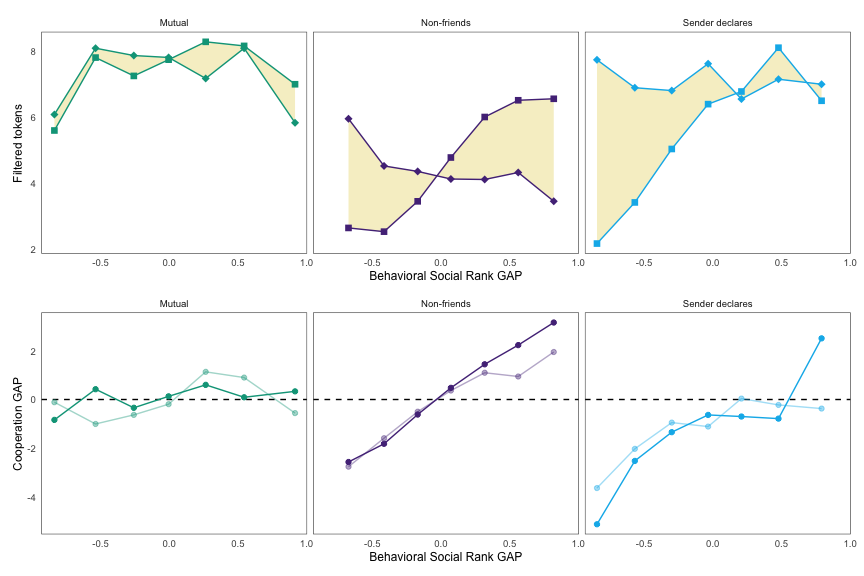

In [ ]:
# Figure 3 panels B and C using the behavioral rank gap: per-child
# averages, 7 equal-width bins (as in 05_figure3_cooperation.R)
bsr_bins <- dyads %>%
  filter(friendship %in% c("Non-friends", "Mutual", "Sender declares")) %>%
  group_by(friendship, sender_id) %>%
  summarise(gap = median(bsr_gap),
            sent = mean(tokens_sent_filtered, na.rm = TRUE),
            received = mean(tokens_received_filtered, na.rm = TRUE),
            coop_observed = mean(coop_gap),
            coop_filtered = mean(coop_gap_filtered, na.rm = TRUE), .groups = "drop") %>%
  group_by(friendship) %>% mutate(bin = cut_interval(gap, 7)) %>%
  group_by(friendship, bin) %>%
  summarise(gap = mean(gap), sent = mean(sent, na.rm = TRUE), received = mean(received, na.rm = TRUE),
            Observed = mean(coop_observed), Filtered = mean(coop_filtered, na.rm = TRUE), .groups = "drop")

friend_colors <- c("Non-friends" = color_non_friends, Mutual = color_mutual, "Sender declares" = color_asymmetric)

row_tokens <- ggplot(bsr_bins, aes(gap, color = friendship)) +
  geom_ribbon(aes(ymin = received, ymax = sent), fill = "#F0E5A8", alpha = 0.6, color = NA) +
  geom_line(aes(y = sent)) + geom_point(aes(y = sent), shape = 18, size = 2.5) +
  geom_line(aes(y = received)) + geom_point(aes(y = received), shape = 15, size = 2) +
  facet_wrap(~ friendship) + scale_color_manual(values = friend_colors) +
  labs(x = "Behavioral Social Rank GAP", y = "Filtered tokens") +
  theme_paper(9) + theme(strip.background = element_blank())

row_gap <- bsr_bins %>%
  pivot_longer(c(Observed, Filtered), names_to = "version", values_to = "coop_gap") %>%
  ggplot(aes(gap, coop_gap, color = friendship, alpha = version)) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_line() + geom_point() +
  facet_wrap(~ friendship) + scale_color_manual(values = friend_colors) +
  scale_alpha_manual(values = c(Observed = 0.4, Filtered = 1)) +
  labs(x = "Behavioral Social Rank GAP", y = "Cooperation GAP") +
  theme_paper(9) + theme(strip.background = element_blank())

figure_s29 <- row_tokens / row_gap
figure_s29

## Figure S30

In [ ]:
# BSR against other student characteristics (within-class z-scores)
nominations_received <- dyads %>%
  group_by(student_id = receiver_id) %>%
  summarise(friendship = sum(nom_q3), popular = sum(nom_q4),
            liked = sum(nom_q1), disliked = sum(nom_q2))

bsr_correlates <- students %>%
  left_join(nominations_received, by = "student_id") %>%
  group_by(class_id) %>%
  mutate(across(c(social_rank, friendship, popular, liked, disliked, attendance, gpa),
                ~ (.x - mean(.x)) / sd(.x))) %>%
  ungroup() %>%
  select(bsr, `Social Rank` = social_rank, `Friendship nominations` = friendship,
         `Popular nominations` = popular, `Liked (hang out)` = liked,
         `Disliked (not hang out)` = disliked, Attendance = attendance, GPA = gpa) %>%
  pivot_longer(-bsr)

bsr_correlates %>% group_by(name) %>% summarise(r = cor(bsr, value, use = "complete.obs"))

name,r
Attendance,0.1277592
Disliked (not hang out),-0.4049296
Friendship nominations,0.4866695
GPA,0.3744739
Liked (hang out),0.5149528
Popular nominations,0.3998075
Social Rank,0.4719115


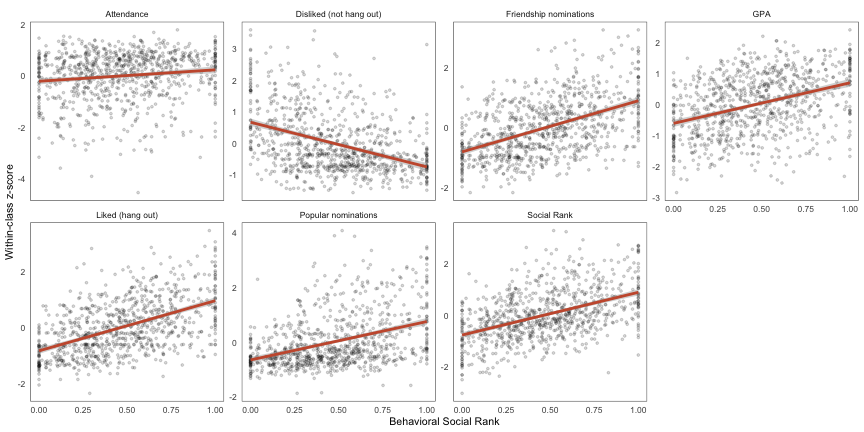

In [ ]:
figure_s30

In [ ]:
iwalk(table_s52, ~ save_table(.x, paste0("S9_table_s52_observed_", str_replace_all(tolower(.y), "[^a-z]+", "_"))))
iwalk(table_s53, ~ save_table(.x, paste0("S9_table_s53_filtered_", str_replace_all(tolower(.y), "[^a-z]+", "_"))))
iwalk(table_s54, ~ save_table(.x, paste0("S9_table_s54_asymmetric_", str_replace_all(tolower(.y), "[^a-z]+", "_"))))
write_csv(students %>% select(student_id, class_id, bsr_pagerank, bsr), here("data", "generated", "behavioral_rank.csv"))
save_si_figure(figure_s29, "S9_figure_s29_bsr_cooperation", 9, 6)
save_si_figure(figure_s30, "S9_figure_s30_bsr_correlates", 9, 4.5)